# Periodic advection–diffusion: a method comparison

**Source:** CompSci §§5.1–5.3.5, pp. 37–48 · [Source map](../docs/SOURCES.md) · [Course index](../README.md)

Combine upwind advection and centred diffusion for constant $u>0$. The explicit weights are $r,\ 1-\nu-2r,\ \nu+r$ on right, centre and left. Their nonnegativity gives a sufficient stability condition $\nu+2r\le1$. Backward Euler has factor $G=[1+\nu(1-e^{-i\theta})+4r\sin^2(\theta/2)]^{-1}$. The denominator has real part at least one, so every mode is bounded even for large $h$.

Here the same periodic upwind spatial operator is advanced with explicit Euler, backward Euler and Crank–Nicolson. Fourier diagonalisation solves the circulant system exactly up to roundoff. This is a small synthetic tracer experiment, not a forecast.

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.22,
                     "axes.spines.top": False, "axes.spines.right": False})
root = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "01_Foundations").is_dir() and (p / "requirements.txt").is_file())
out = root / "assets" / "figures"
out.mkdir(parents=True, exist_ok=True)

def show(fig, name):
    fig.tight_layout()
    fig.savefig(out / (name + ".png"), dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)

Matplotlib is building the font cache; this may take a moment.


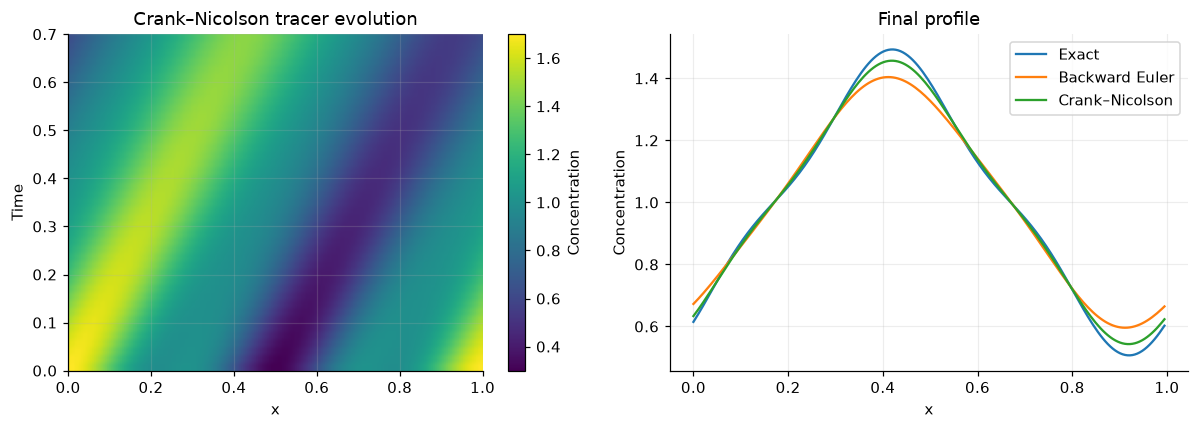

Explicit max |G|: 15.128


In [2]:
N=192; x=np.arange(N)/N; u=.6; D=.005; T=.7; h=T/42
theta=2*np.pi*np.fft.fftfreq(N)
z=-u*h*N*(1-np.exp(-1j*theta))-4*D*h*N*N*np.sin(theta/2)**2
y0=1+.5*np.cos(2*np.pi*x)+.2*np.cos(6*np.pi*x)
def exact(t):
    return 1+.5*np.exp(-D*(2*np.pi)**2*t)*np.cos(2*np.pi*(x-u*t)) + .2*np.exp(-D*(6*np.pi)**2*t)*np.cos(6*np.pi*(x-u*t))
def evolution(G):
    return np.fft.ifft(np.fft.fft(y0)[None,:]*G[None,:]**np.arange(43)[:,None],axis=1).real
be=evolution(1/(1-z)); cn=evolution((1+z/2)/(1-z/2))
fig,ax=plt.subplots(1,2,figsize=(11,4))
im=ax[0].imshow(cn,origin="lower",aspect="auto",extent=(0,1,0,T),cmap="viridis")
fig.colorbar(im,ax=ax[0],label="Concentration")
ax[0].set(xlabel="x",ylabel="Time",title="Crank–Nicolson tracer evolution")
for label,y in [("Exact",exact(T)),("Backward Euler",be[-1]),("Crank–Nicolson",cn[-1])]:
    ax[1].plot(x,y,label=label)
ax[1].set(xlabel="x",ylabel="Concentration",title="Final profile"); ax[1].legend()
show(fig,"06-tracer")
assert np.max(abs(1+z))>1
for y in [be,cn]:
    assert np.allclose(y.mean(axis=1),1)
    assert np.max(np.diff(np.mean(y*y,axis=1)))<1e-12
assert np.max(abs(cn[-1]-exact(T)))<.045
print("Explicit max |G|:",np.max(abs(1+z)))

## Worked exercise

**Why do stable profiles still differ from the exact profile?** Upwind spatial truncation adds numerical diffusion, and both implicit methods introduce time error. Refine space and time together to distinguish these effects.